# Análise exploratória — dengue em São Paulo (InfoDengue)

Este notebook analisa o snapshot do InfoDengue (`data/dengue_sp_snapshot.csv`) e **propõe**
visualizações para o dashboard. Ele é o primeiro portão de aprovação humana do projeto: quem decide
o que entra no painel é o responsável, marcando as opções em
[`docs/visualizacoes.md`](../docs/visualizacoes.md). A implementação do dashboard só começa depois disso.

Os indicadores vêm do módulo compartilhado `smart_hospitals.data`, o mesmo que o dashboard e o
MCP server usam, para que os números daqui sejam os mesmos que aparecerão no painel.

Seções:
1. Visão geral dos dados
2. Série temporal e níveis de alerta
3. Padrões sazonais
4. Indicadores epidemiológicos (Rt e alertas)
5. Tendência recente (últimas 12 semanas)
6. Propostas de visualização para o dashboard

> Os números citados nos textos referem-se ao snapshot até a SE 202640 (semana de 2026-10-04).
> Ao reexecutar com um snapshot novo, confira-os contra as saídas das células.
>
> Os gráficos de análise são estáticos (matplotlib/seaborn) e aparecem no GitHub. Os mockups da
> seção 6 usam Plotly, a biblioteca do dashboard, e só aparecem ao abrir o notebook no Jupyter.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from plotly.subplots import make_subplots

from smart_hospitals.data import (
    calcular_situacao_atual,
    calcular_tendencia,
    comparativo_sazonal,
    get_reference_date,
    load_snapshot,
)
from smart_hospitals.data.indicators import LEVEL_MAP

pio.renderers.default = "notebook_connected"  # carrega o plotly.js da CDN em vez de embutir
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4.5)
pd.set_option("display.max_columns", 40)

LEVEL_COLORS = {
    "verde": "#2e7d32",
    "amarelo": "#f9a825",
    "laranja": "#ef6c00",
    "vermelho": "#c62828",
}
LEVEL_NAMES = [LEVEL_MAP[n] for n in sorted(LEVEL_MAP)]


def fmt_int(valor: float) -> str:
    """Inteiro com separador de milhar brasileiro (1.234)."""
    return f"{valor:,.0f}".replace(",", ".")

## 1. Visão geral dos dados

In [2]:
df = load_snapshot()
df["ano"] = df["SE"] // 100
df["semana"] = df["SE"] % 100
df["mes"] = df["data_iniSE"].dt.month
df["nivel_nome"] = df["nivel"].map(LEVEL_MAP)
ano_ref = int(df["ano"].iloc[-1])

print(f"Período: {df['data_iniSE'].min():%Y-%m-%d} a {get_reference_date(df):%Y-%m-%d}")
print(f"Semanas epidemiológicas: {len(df)} (SE {df['SE'].iloc[0]} a {df['SE'].iloc[-1]})")
intervalos = df["data_iniSE"].diff().dropna().dt.days.value_counts()
print(f"Intervalo entre semanas consecutivas (dias): {intervalos.to_dict()}")
print(f"Anos com 53 semanas: {sorted(df.loc[df['semana'] == 53, 'ano'].tolist())}")

Período: 2010-01-03 a 2026-10-04
Semanas epidemiológicas: 875 (SE 201001 a 202640)
Intervalo entre semanas consecutivas (dias): {7: 874}
Anos com 53 semanas: [2014, 2020, 2025]


In [3]:
colunas_usadas = [
    "SE",
    "data_iniSE",
    "casos",
    "casos_est",
    "casos_est_min",
    "casos_est_max",
    "Rt",
    "p_rt1",
    "nivel",
    "p_inc100k",
]
df[colunas_usadas].dtypes.to_frame("dtype").T

,SE,data_iniSE,casos,casos_est,casos_est_min,casos_est_max,Rt,p_rt1,nivel,p_inc100k
dtype,int64,datetime64[us],int64,float64,int64,float64,float64,float64,int64,float64


In [4]:
df[colunas_usadas].tail()

,SE,data_iniSE,casos,casos_est,casos_est_min,casos_est_max,Rt,p_rt1,nivel,p_inc100k
870,202636,2026-09-06,944,996.0,963,1060.0,0.909894,0.015464,1,8.163814
871,202637,2026-09-13,967,1047.0,998,1154.0,1.008168,0.573693,1,8.581841
872,202638,2026-09-20,1077,1207.0,1132,1391.0,1.173892,0.999923,1,9.893296
873,202639,2026-09-27,1058,1344.0,1151,1838.0,1.240070,1.000000,3,11.016231
874,202640,2026-10-04,352,1161.0,582,3114.0,0.982863,0.337848,3,9.516253


In [5]:
faltantes = df[colunas_usadas].isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("semanas_sem_valor")
faltantes["anos"] = [sorted(df.loc[df[c].isna(), "ano"].unique().tolist()) for c in faltantes.index]
faltantes

,semanas_sem_valor,anos
casos_est_max,40,"[2015, 2024, 2025]"


Só `casos_est_max` tem lacunas: o InfoDengue deixa o limite superior do nowcast vazio em algumas
semanas. O dashboard precisa desenhar a banda de incerteza com falhas nesses pontos, sem inventar
valores (decisão registrada no Basic Memory: NaN não vira 0).

In [6]:
anuais = df.groupby("ano").agg(
    semanas=("SE", "size"),
    casos_notificados=("casos", "sum"),
    casos_estimados=("casos_est", "sum"),
    pico_semanal=("casos_est", "max"),
    semanas_vermelho=("nivel", lambda s: int((s == 4).sum())),
)
anuais.style.format("{:,.0f}")

,semanas,casos_notificados,casos_estimados,pico_semanal,semanas_vermelho
ano,,,,,
2010,52,"21,191","21,191","1,765",12
2011,52,"16,088","16,088","1,111",6
2012,52,"8,177","8,177",365,0
2013,52,"17,301","17,301","1,680",7
2014,53,"63,245","63,245","7,679",16
2015,52,"85,547","85,547","12,367",17
2016,52,"11,938","11,938",659,0
2017,52,"9,202","9,202",372,0
2018,52,"10,920","10,920",696,0


## 2. Série temporal e níveis de alerta

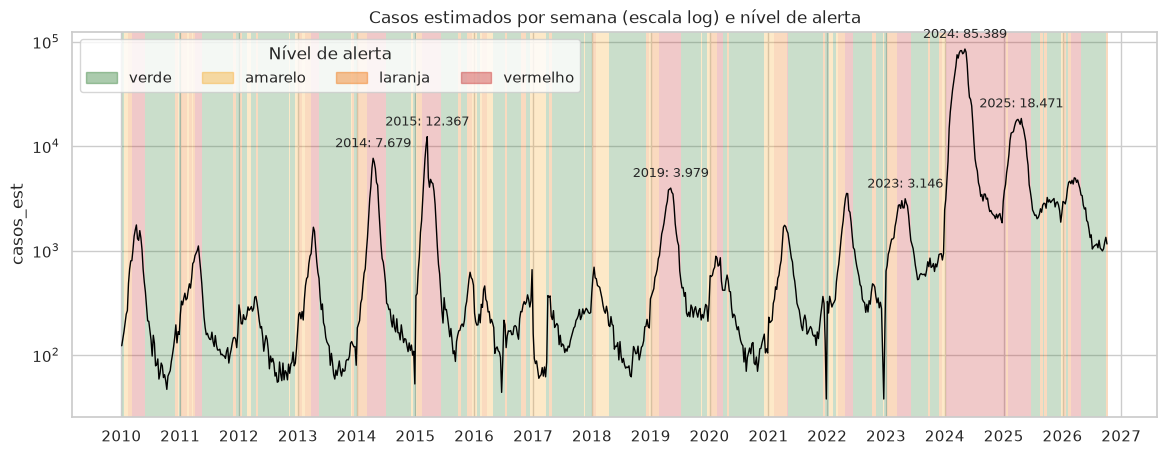

Limiar de surto: 46.406 casos/ano. Anos de surto: [2014, 2015, 2019, 2023, 2024, 2025]
Trechos contínuos de nível de alerta: 118


In [7]:
def faixas_de_nivel(dados: pd.DataFrame) -> pd.DataFrame:
    """Trechos contínuos com o mesmo nível de alerta (início, fim exclusivo, nível)."""
    trecho = (dados["nivel"] != dados["nivel"].shift()).cumsum()
    faixas = dados.groupby(trecho).agg(
        inicio=("data_iniSE", "first"), ultima=("data_iniSE", "last"), nivel=("nivel_nome", "first")
    )
    faixas["fim"] = faixas["ultima"] + pd.Timedelta(days=7)
    return faixas.drop(columns="ultima").reset_index(drop=True)


faixas = faixas_de_nivel(df)

# Surtos: anos com total estimado acima do dobro da mediana anual (anos completos).
completos = anuais[anuais["semanas"] >= 52]
limiar_surto = 2 * completos["casos_estimados"].median()
anos_surto = completos.index[completos["casos_estimados"] > limiar_surto].tolist()
picos = df.loc[df[df["ano"].isin(anos_surto)].groupby("ano")["casos_est"].idxmax()]

fig, ax = plt.subplots(figsize=(14, 5))
for f in faixas.itertuples():
    ax.axvspan(f.inicio, f.fim, color=LEVEL_COLORS[f.nivel], alpha=0.25, lw=0)
ax.plot(df["data_iniSE"], df["casos_est"], color="black", lw=1)
ax.set_yscale("log")
for p in picos.itertuples():
    ax.annotate(
        f"{p.ano}: {fmt_int(p.casos_est)}",
        (p.data_iniSE, p.casos_est),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
handles = [plt.Rectangle((0, 0), 1, 1, color=LEVEL_COLORS[n], alpha=0.4) for n in LEVEL_NAMES]
ax.legend(handles, LEVEL_NAMES, title="Nível de alerta", loc="upper left", ncol=4)
ax.set(title="Casos estimados por semana (escala log) e nível de alerta", ylabel="casos_est")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

print(f"Limiar de surto: {fmt_int(limiar_surto)} casos/ano. Anos de surto: {anos_surto}")
print(f"Trechos contínuos de nível de alerta: {len(faixas)}")

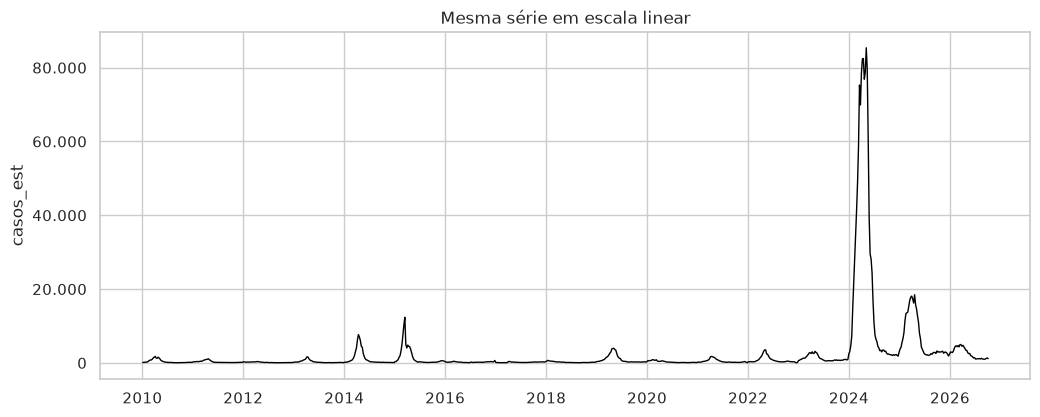

In [8]:
fig, ax = plt.subplots()
ax.plot(df["data_iniSE"], df["casos_est"], color="black", lw=1)
ax.set(title="Mesma série em escala linear", ylabel="casos_est")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_int(v)))
plt.show()

Em escala linear, o surto de 2024 (dezenas de milhares de casos por semana) achata todos os outros
anos. Por isso a série principal do dashboard deve usar escala log ou abrir num recorte recente
(ex.: últimos 2–3 anos) com opção de ver a série completa.

## 3. Padrões sazonais

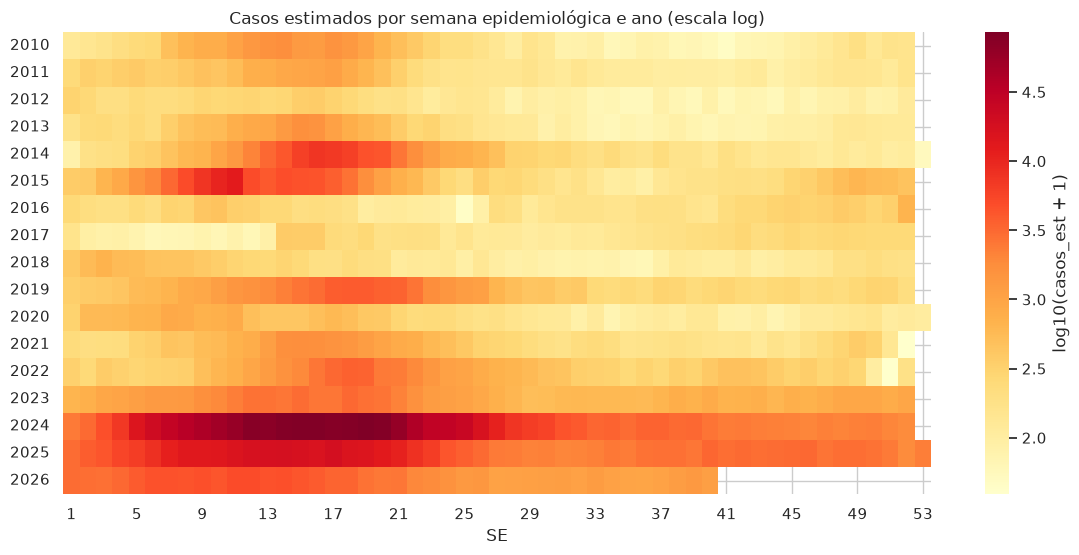

In [9]:
heat = df.pivot_table(index="ano", columns="semana", values="casos_est")
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    np.log10(heat + 1),
    cmap="YlOrRd",
    ax=ax,
    cbar_kws={"label": "log10(casos_est + 1)"},
    xticklabels=4,
)
ax.set(title="Casos estimados por semana epidemiológica e ano (escala log)", xlabel="SE", ylabel="")
plt.show()

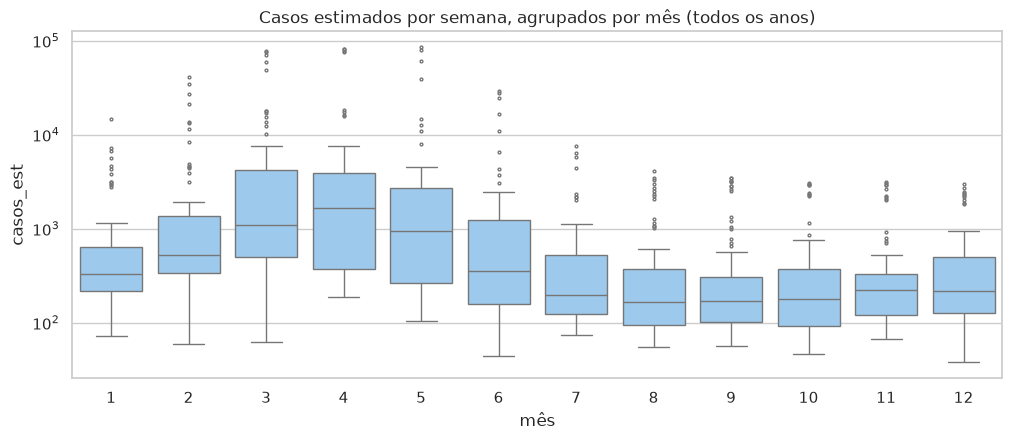

In [10]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="mes", y="casos_est", ax=ax, color="#90caf9", fliersize=2)
ax.set_yscale("log")
ax.set(title="Casos estimados por semana, agrupados por mês (todos os anos)", xlabel="mês")
plt.show()

10 SEs com maior peso mediano: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Peso dessas semanas: 44% do ano (mediana)
SEs de menor peso: [31, 35, 36, 37, 41, 42, 43, 44, 45, 53]


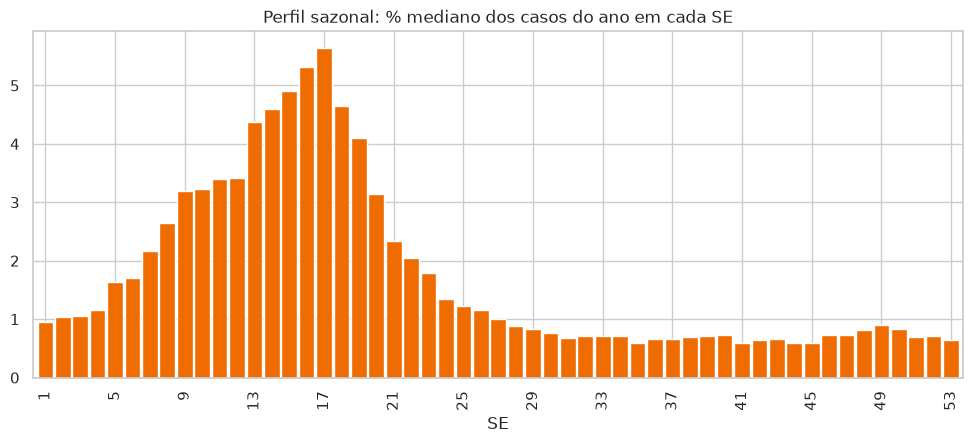

In [11]:
# Peso de cada SE no ano: normaliza pelo total anual para que 2024 não domine a mediana.
completos_df = df[df["ano"].isin(completos.index)]
peso = completos_df["casos_est"] / completos_df.groupby("ano")["casos_est"].transform("sum")
perfil = (peso * 100).groupby(completos_df["semana"]).median().rename("% mediano do ano")

print(f"10 SEs com maior peso mediano: {sorted(perfil.nlargest(10).index.tolist())}")
print(f"Peso dessas semanas: {perfil.nlargest(10).sum():.0f}% do ano (mediana)")
print(f"SEs de menor peso: {sorted(perfil.nsmallest(10).index.tolist())}")

fig, ax = plt.subplots()
perfil.plot.bar(ax=ax, color="#ef6c00", width=0.9)
ax.set(title="Perfil sazonal: % mediano dos casos do ano em cada SE", xlabel="SE")
ax.xaxis.set_major_locator(plt.MultipleLocator(4))
plt.show()

A sazonalidade é forte e estável: nos anos completos, as SEs 10 a 19 (de março a meados de maio)
concentram cerca de 44% dos casos do ano, e o segundo semestre é sempre baixo. Isso vale tanto
nos anos normais quanto nos de surto (2014, 2015, 2019, 2023, 2024, 2025), que só deslocam a
curva para cima. Comparar o ano atual com a mesma semana dos anos anteriores é, portanto, uma
referência útil.

## 4. Indicadores epidemiológicos

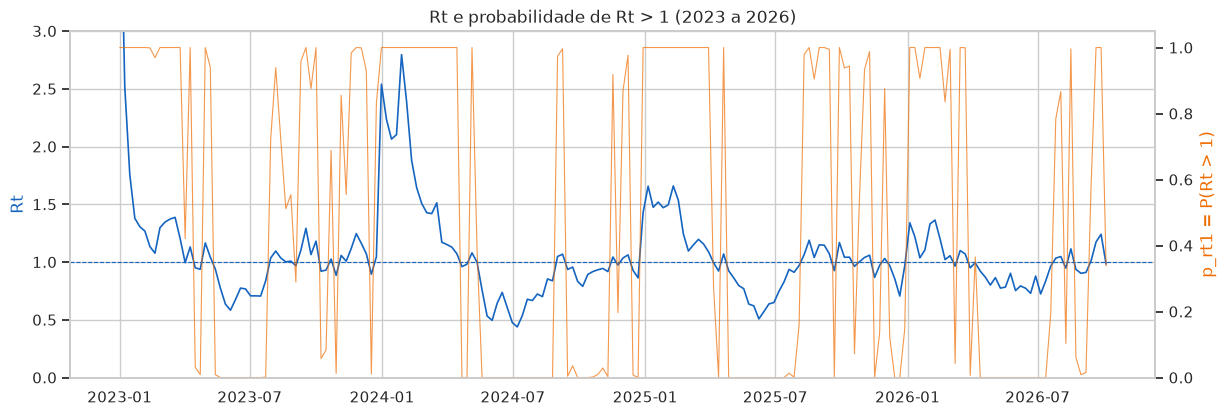

In [12]:
recorte = df[df["ano"] >= ano_ref - 3]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(recorte["data_iniSE"], recorte["Rt"], color="#1565c0", lw=1.2, label="Rt")
ax.axhline(1, color="#1565c0", ls="--", lw=0.8)
ax.set_ylim(0, 3)  # picos isolados de Rt (até 4,6 na virada de 2023) achatariam o eixo
ax.set_ylabel("Rt", color="#1565c0")
ax2 = ax.twinx()
ax2.plot(recorte["data_iniSE"], recorte["p_rt1"], color="#ef6c00", lw=0.8, alpha=0.7, label="p_rt1")
ax2.set(ylim=(0, 1.05))
ax2.set_ylabel("p_rt1 = P(Rt > 1)", color="#ef6c00")
ax2.grid(False)
ax.set_title(f"Rt e probabilidade de Rt > 1 ({ano_ref - 3} a {ano_ref})")
plt.show()

**Rt × casos futuros.** Se o Rt antecipa a curva, ele deve se correlacionar com o *crescimento* dos
casos nas semanas seguintes. Usamos a correlação de Spearman entre o Rt da semana *t* e a variação
log de `casos_est` entre *t* e *t + lag*. É uma análise exploratória para escolher o que mostrar,
não um modelo de previsão (a fase 1 não faz previsão numérica). As 5 primeiras semanas de 2010 têm
Rt = 0 (aquecimento do estimador) e ficam de fora.

lag (semanas),1,2,3,4,5,6,7,8
Rt x crescimento,0.31,0.37,0.41,0.41,0.41,0.41,0.38,0.35
p_rt1 x crescimento,0.33,0.39,0.43,0.44,0.43,0.42,0.39,0.35


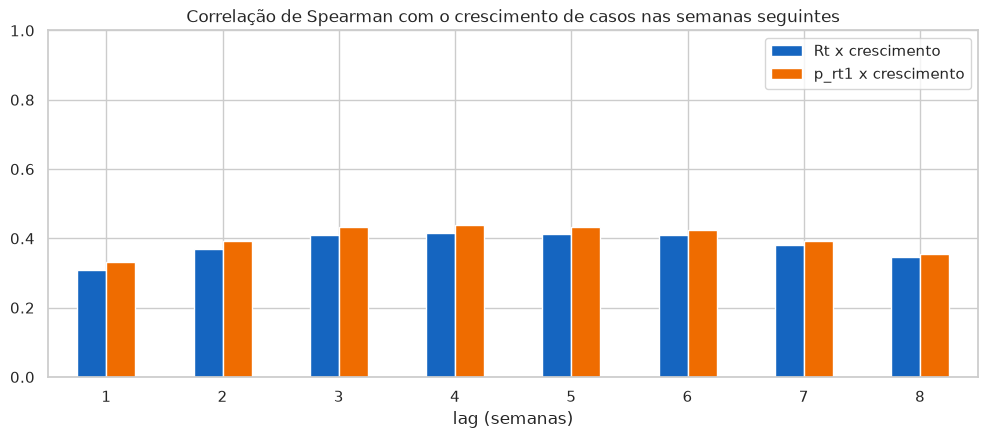

In [13]:
def spearman(a: pd.Series, b: pd.Series) -> float:
    """Spearman como Pearson sobre os postos (evita depender do scipy)."""
    pares = pd.concat([a, b], axis=1).dropna()
    return float(pares.iloc[:, 0].rank().corr(pares.iloc[:, 1].rank()))


# O crescimento é calculado na série completa (semanas consecutivas) e só depois filtrado.
log_casos = np.log1p(df["casos_est"])
valido = df["Rt"] > 0
lags = range(1, 9)  # lag 0 não tem crescimento a medir
crescimento = {lag: (log_casos.shift(-lag) - log_casos)[valido] for lag in lags}
corr = pd.DataFrame(
    {
        "Rt x crescimento": [spearman(df.loc[valido, "Rt"], crescimento[lag]) for lag in lags],
        "p_rt1 x crescimento": [
            spearman(df.loc[valido, "p_rt1"], crescimento[lag]) for lag in lags
        ],
    },
    index=pd.Index(lags, name="lag (semanas)"),
)
display(corr.round(2).T)

ax = corr.plot.bar(color=["#1565c0", "#ef6c00"], rot=0)
ax.set(title="Correlação de Spearman com o crescimento de casos nas semanas seguintes", ylim=(0, 1))
plt.show()

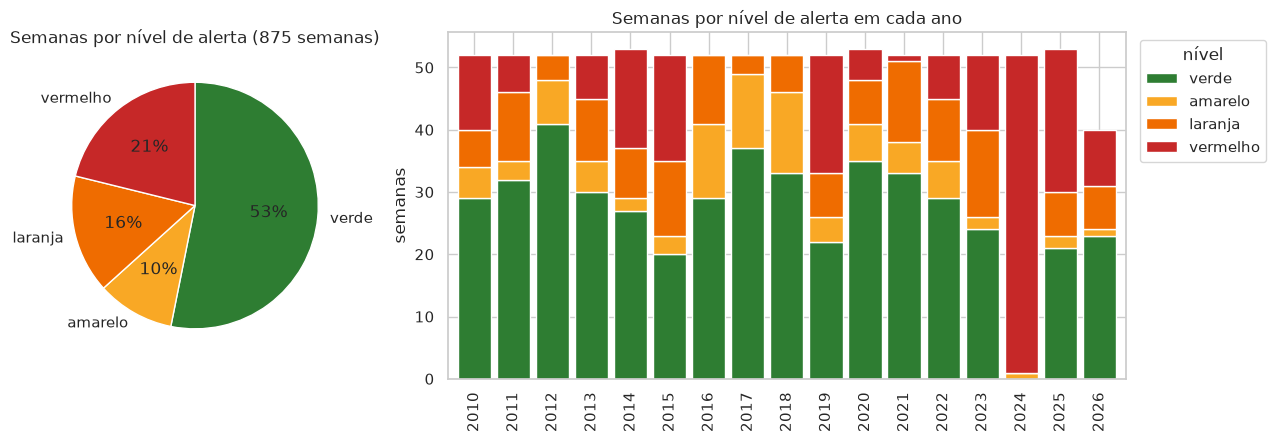

In [14]:
dist = df["nivel_nome"].value_counts().reindex(LEVEL_NAMES)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2.2]})
ax1.pie(
    dist,
    labels=dist.index,
    colors=[LEVEL_COLORS[n] for n in dist.index],
    autopct="%1.0f%%",
    startangle=90,
    counterclock=False,
)
ax1.set_title(f"Semanas por nível de alerta ({len(df)} semanas)")
por_ano = pd.crosstab(df["ano"], df["nivel_nome"]).reindex(columns=LEVEL_NAMES, fill_value=0)
por_ano.plot.bar(stacked=True, ax=ax2, color=[LEVEL_COLORS[n] for n in LEVEL_NAMES], width=0.85)
ax2.set(title="Semanas por nível de alerta em cada ano", xlabel="", ylabel="semanas")
ax2.legend(title="nível", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

Rt e p_rt1 têm correlação positiva moderada (≈ 0,3 a 0,44) com o crescimento dos casos nas semanas
seguintes, mais forte entre 3 e 5 semanas à frente. São sinais antecipados úteis para direção da
curva, não para estimar quantos casos virão. Mais da metade das semanas da série (53%) é verde; o
surto de 2024 passou praticamente o ano todo em vermelho.

## 5. Tendência recente (últimas 12 semanas)

In [15]:
recentes = df.tail(12).copy()
recentes["variacao_%"] = recentes["casos_est"].pct_change() * 100
recentes["sub_notificacao_%"] = (1 - recentes["casos"] / recentes["casos_est"]) * 100
cols = [
    "SE",
    "data_iniSE",
    "casos",
    "casos_est",
    "casos_est_min",
    "casos_est_max",
    "variacao_%",
    "sub_notificacao_%",
    "Rt",
    "p_rt1",
    "nivel_nome",
]
recentes[cols].style.format(
    {
        "data_iniSE": "{:%Y-%m-%d}",
        "casos_est": "{:,.0f}",
        "casos_est_min": "{:,.0f}",
        "casos_est_max": "{:,.0f}",
        "variacao_%": "{:+.1f}",
        "sub_notificacao_%": "{:.0f}",
        "Rt": "{:.2f}",
        "p_rt1": "{:.2f}",
    },
    na_rep="—",
).hide(axis="index")

SE,data_iniSE,casos,casos_est,casos_est_min,casos_est_max,variacao_%,sub_notificacao_%,Rt,p_rt1,nivel_nome
202629,2026-07-19,1119,"1,119","1,119","1,119",—,0,0.96,0.19,verde
202630,2026-07-26,1136,"1,136","1,136","1,136",+1.5,0,1.03,0.78,verde
202631,2026-08-02,1159,"1,162","1,159","1,172",+2.3,0,1.05,0.87,verde
202632,2026-08-09,1059,"1,067","1,060","1,085",-8.2,1,0.95,0.10,verde
202633,2026-08-16,1245,"1,259","1,248","1,281",+18.0,1,1.11,1.00,verde
202634,2026-08-23,1041,"1,063","1,048","1,095",-15.6,2,0.94,0.06,verde
202635,2026-08-30,997,"1,030","1,009","1,074",-3.1,3,0.90,0.01,verde
202636,2026-09-06,944,996,963,"1,060",-3.3,5,0.91,0.02,verde
202637,2026-09-13,967,"1,047",998,"1,154",+5.1,8,1.01,0.57,verde
202638,2026-09-20,1077,"1,207","1,132","1,391",+15.3,11,1.17,1.00,verde


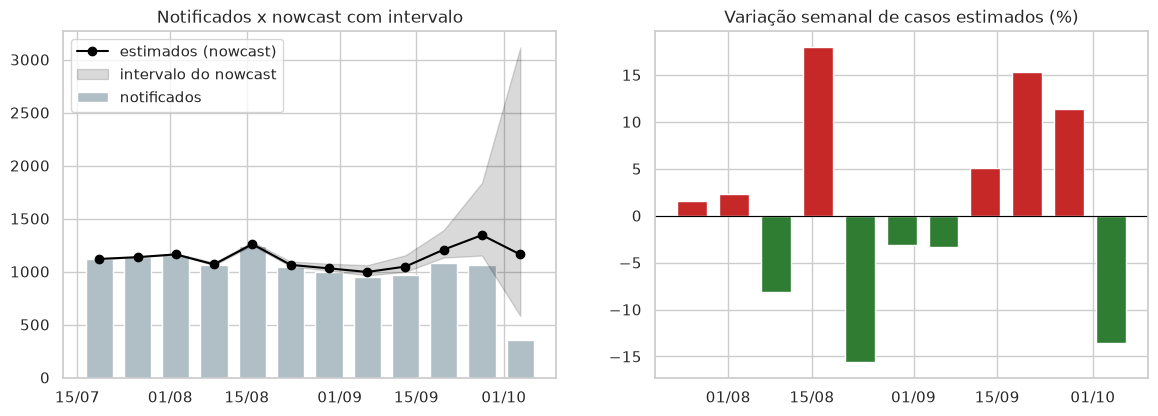

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
x = recentes["data_iniSE"]
ax1.bar(x, recentes["casos"], width=5, color="#b0bec5", label="notificados")
ax1.plot(x, recentes["casos_est"], color="black", marker="o", label="estimados (nowcast)")
ax1.fill_between(
    x,
    recentes["casos_est_min"],
    recentes["casos_est_max"],
    color="black",
    alpha=0.15,
    label="intervalo do nowcast",
)
ax1.set(title="Notificados x nowcast com intervalo")
ax1.legend()
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))

var = recentes["variacao_%"].iloc[1:]
ax2.bar(x.iloc[1:], var, width=5, color=np.where(var > 0, "#c62828", "#2e7d32"))
ax2.axhline(0, color="black", lw=0.8)
ax2.set(title="Variação semanal de casos estimados (%)")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.show()

Na semana mais recente foram notificados 352 casos, contra 1.161 estimados pelo nowcast (intervalo
de 582 a 3.114): o atraso de notificação faz a última semana parecer uma queda de dois terços.
O intervalo do nowcast também se alarga nas últimas semanas. Mostrar só notificados daria a falsa
impressão de queda; o painel deve usar `casos_est` com o
intervalo, como o MCP já faz.

In [17]:
def ou_traco(valor: float | None) -> str:
    """Valor formatado, ou travessão quando o módulo de dados devolve None."""
    return "—" if valor is None else fmt_int(valor)


situacao = calcular_situacao_atual(df)
tendencia = calcular_tendencia(df, semanas=4)
sazonal = comparativo_sazonal(df)

pd.Series(
    {
        "Semana de referência": situacao.data_referencia,
        "Casos estimados": fmt_int(situacao.casos_est),
        "Intervalo": (
            f"{fmt_int(situacao.casos_est_min)} a {fmt_int(situacao.casos_est_max)}"
            if situacao.casos_est_min is not None and situacao.casos_est_max is not None
            else "não informado"
        ),
        "Casos notificados": fmt_int(situacao.casos_notificados),
        "Variação semanal": f"{situacao.variacao_semanal:+.1f}%",
        "Incidência / 100 mil": f"{situacao.incidencia_100k:.1f}",
        "Nível de alerta": situacao.nivel_alerta,
        "Rt / p_rt1": f"{situacao.rt:.2f} / {situacao.p_rt1:.2f}",
        "Tendência (4 semanas)": (
            f"{tendencia.tendencia_resumo} (Rt médio {tendencia.rt_medio}, "
            f"p_rt1 médio {tendencia.p_rt1_medio})"
        ),
        f"SE {sazonal['semana_epidemiologica']}: ano atual x histórico": (
            f"{ou_traco(sazonal['ano_atual'])} x média {ou_traco(sazonal['media_historica'])} "
            f"(mín. {ou_traco(sazonal['minimo'])}, máx. {ou_traco(sazonal['maximo'])}, "
            f"{sazonal['anos_comparados']} anos)"
        ),
    },
    name="valor",
).to_frame()

,valor
Semana de referência,2026-10-04
Casos estimados,1.161
Intervalo,582 a 3.114
Casos notificados,352
Variação semanal,-13.6%
Incidência / 100 mil,9.5
Nível de alerta,laranja
Rt / p_rt1,0.98 / 0.34
Tendência (4 semanas),"alta (Rt médio 1.1, p_rt1 médio 0.73)"
SE 40: ano atual x histórico,"1.161 x média 550 (mín. 57, máx. 3.238, 16 anos)"


## 6. Propostas de visualização para o dashboard

Cada proposta abaixo traz o que mostra, o achado que a justifica e um mockup em Plotly (a biblioteca
do dashboard). As opções estão listadas em [`docs/visualizacoes.md`](../docs/visualizacoes.md) para
aprovação.

### 6.1 Série temporal principal com níveis de alerta (Plotly interativo)
- **Mostra:** `casos_est` com faixas coloridas pelo nível de alerta, zoom e seletor de período.
  A banda de incerteza aparece só nas semanas de nowcast (as mais recentes): nas semanas
  consolidadas o InfoDengue informa mínimo = máximo = `casos_est`, ou deixa o máximo vazio.
- **Por quê:** é a visão que conecta a situação atual ao histórico. A escala log (ou o recorte
  inicial nos anos recentes) evita que o surto de 2024 esconda os demais anos (seção 2).

In [18]:
def eixo_casos_log(fig: go.Figure) -> None:
    """Eixo y em log com marcas legíveis (100, 1 mil, 10 mil...) e números no formato brasileiro."""
    marcas = [10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000]
    rotulos = [f"{v // 1000} mil" if v >= 1000 else str(v) for v in marcas]
    fig.update_yaxes(
        type="log", tickvals=marcas, ticktext=rotulos, title="Casos por semana (escala logarítmica)"
    )
    fig.update_layout(separators=",.")  # decimal com vírgula e milhar com ponto, também no hover


def mockup_serie(dados: pd.DataFrame) -> go.Figure:
    fig = go.Figure()
    # Faixas de vrect não entram na legenda: um marcador vazio por nível faz esse papel.
    for nome in LEVEL_NAMES:
        fig.add_trace(
            go.Scatter(
                x=[None],
                y=[None],
                mode="markers",
                name=nome,
                marker={
                    "symbol": "square",
                    "size": 14,
                    "color": LEVEL_COLORS[nome],
                    "opacity": 0.4,
                },
                legendgroup="alerta",
                legendgrouptitle_text="Nível de alerta",
            )
        )
    for f in faixas_de_nivel(dados).itertuples():
        fig.add_vrect(
            x0=f.inicio, x1=f.fim, fillcolor=LEVEL_COLORS[f.nivel], opacity=0.2, line_width=0
        )
    # O InfoDengue só informa intervalo nas semanas de nowcast (as mais recentes); nas consolidadas
    # min = max = casos_est ou max vem vazio. A banda é um polígono por trecho contínuo de semanas
    # com intervalo, para não ligar trechos separados por lacunas.
    com_intervalo = dados["casos_est_max"] > dados["casos_est_min"]
    intervalo_txt = np.where(
        com_intervalo,
        " ("
        + dados["casos_est_min"].map(fmt_int)
        + " a "
        + dados["casos_est_max"].map(fmt_int)
        + ")",
        "",
    )
    trechos = dados[com_intervalo].groupby((~com_intervalo).cumsum()[com_intervalo])
    for i, (_, t) in enumerate(trechos):
        fig.add_trace(
            go.Scatter(
                x=pd.concat([t["data_iniSE"], t["data_iniSE"][::-1]]),
                y=pd.concat([t["casos_est_max"], t["casos_est_min"][::-1]]),
                fill="toself",
                fillcolor="rgba(0,0,0,0.15)",
                line_width=0,
                hoverinfo="skip",
                name="intervalo do nowcast (semanas recentes)",
                legendgroup="intervalo",
                showlegend=i == 0,
            )
        )
    fig.add_trace(
        go.Scatter(
            x=dados["data_iniSE"],
            y=dados["casos_est"],
            name="casos estimados",
            line={"color": "black", "width": 1.5},
            customdata=np.column_stack([dados["SE"], dados["nivel_nome"], intervalo_txt]),
            hovertemplate=(
                "SE %{customdata[0]}<br>%{y:,.0f} casos%{customdata[2]}<br>nível %{customdata[1]}"
            ),
        )
    )
    inicio_padrao = dados["data_iniSE"].iloc[-1] - pd.DateOffset(years=3)
    fig.update_xaxes(
        type="date",  # explícito: os marcadores da legenda vêm antes da série e não têm datas
        range=[inicio_padrao, dados["data_iniSE"].iloc[-1]],
        rangeslider_visible=True,
        rangeselector={
            "buttons": [
                {"count": 6, "label": "6m", "step": "month", "stepmode": "backward"},
                {"count": 1, "label": "1a", "step": "year", "stepmode": "backward"},
                {"count": 3, "label": "3a", "step": "year", "stepmode": "backward"},
                {"step": "all", "label": "tudo"},
            ]
        },
    )
    eixo_casos_log(fig)
    fig.update_layout(
        title="Casos estimados de dengue — São Paulo", height=480, hovermode="x unified"
    )
    return fig


mockup_serie(df).show()

### 6.2 Card de situação atual (KPIs)
- **Mostra:** casos estimados da semana (com variação semanal), nível de alerta, Rt e incidência
  por 100 mil — os mesmos campos de `calcular_situacao_atual`.
- **Por quê:** responde de imediato "como está agora?", que é a pergunta do caso de uso (compra
  antecipada de medicamentos). No Streamlit vira uma linha de `st.metric`.

In [19]:
anterior = float(df["casos_est"].iloc[-2])
kpis = make_subplots(rows=1, cols=4, specs=[[{"type": "indicator"}] * 4])
kpis.add_trace(
    go.Indicator(
        mode="number+delta",
        value=situacao.casos_est,
        title="Casos estimados",
        delta={
            "reference": anterior,
            "relative": True,
            "valueformat": ".1%",
            "increasing": {"color": "#c62828"},
            "decreasing": {"color": "#2e7d32"},
        },
    ),
    1,
    1,
)
kpis.add_trace(
    go.Indicator(
        mode="number",
        value=LEVEL_NAMES.index(situacao.nivel_alerta) + 1,
        title=f"Nível de alerta: {situacao.nivel_alerta}",
        number={"font": {"color": LEVEL_COLORS[situacao.nivel_alerta]}},
    ),
    1,
    2,
)
kpis.add_trace(
    go.Indicator(mode="number", value=situacao.rt, title="Rt", number={"valueformat": ".2f"}),
    1,
    3,
)
kpis.add_trace(
    go.Indicator(
        mode="number",
        value=situacao.incidencia_100k,
        title="Incidência / 100 mil",
        number={"valueformat": ".1f"},
    ),
    1,
    4,
)
kpis.update_layout(height=220, title=f"Semana de {situacao.data_referencia}")
kpis.show()

### 6.3 Comparação sazonal
- **Mostra:** a curva do ano corrente sobre a mediana e a faixa mín.–máx. dos anos anteriores,
  por semana epidemiológica.
- **Por quê:** o pico se concentra sempre nas mesmas semanas (seção 3); comparar com o histórico
  diz se o ano está acima ou abaixo do esperado para a época. Usa a mesma regra de
  `comparativo_sazonal` para a base de comparação (só anos anteriores ao de referência), mas
  mostra a **mediana** em vez da média: a média por semana é puxada pelos surtos (2024) e faria
  quase todo ano parecer abaixo do normal. Se o card de KPIs também exibir o comparativo, o
  dashboard deve usar a mesma estatística nos dois lugares.

In [20]:
anteriores = df[df["ano"] < ano_ref].groupby("semana")["casos_est"]
faixa = anteriores.agg(["min", "median", "max"])
atual = df[df["ano"] == ano_ref].set_index("semana")["casos_est"]

saz = go.Figure()
saz.add_trace(go.Scatter(x=faixa.index, y=faixa["max"], line_width=0, showlegend=False))
saz.add_trace(
    go.Scatter(
        x=faixa.index,
        y=faixa["min"],
        fill="tonexty",
        line_width=0,
        fillcolor="rgba(21,101,192,0.15)",
        name=f"mín. a máx. ({df['ano'].min()} a {ano_ref - 1})",
    )
)
saz.add_trace(
    go.Scatter(
        x=faixa.index,
        y=faixa["median"],
        name="mediana histórica",
        line={"color": "#1565c0", "dash": "dash"},
    )
)
saz.add_trace(
    go.Scatter(
        x=atual.index, y=atual.values, name=str(ano_ref), line={"color": "black", "width": 2.5}
    )
)
eixo_casos_log(saz)
saz.update_xaxes(title="semana epidemiológica")
saz.update_layout(title=f"{ano_ref} comparado aos anos anteriores", height=420)
saz.show()

### 6.4 Mini-gráfico de tendência recente (sparkline)
- **Mostra:** as últimas 12 semanas de `casos_est`, sem eixos, ao lado dos KPIs, com a tendência
  das últimas 4 semanas (`calcular_tendencia`: alta / estável / queda) como rótulo.
- **Por quê:** dá a direção da curva sem exigir leitura de gráfico; os notificados recentes
  enganam por causa do atraso (seção 5), então a linha usa o nowcast.

In [21]:
spark = go.Figure(
    go.Scatter(
        x=recentes["data_iniSE"],
        y=recentes["casos_est"],
        mode="lines+markers",
        line={"color": "black"},
        marker={"size": 4},
        hovertemplate="%{x|%d/%m}: %{y:,.0f}",
    )
)
spark.update_xaxes(visible=False)
spark.update_yaxes(visible=False)
spark.update_layout(
    height=120,
    width=360,
    margin={"l": 10, "r": 10, "t": 30, "b": 10},
    title={"text": f"12 semanas · tendência: {tendencia.tendencia_resumo}", "font": {"size": 13}},
)
spark.show()

### 6.5 Indicadores Rt e probabilidade de transmissão em crescimento
- **Mostra:** dois medidores lado a lado. O do Rt tem faixas < 0,9 (queda), 0,9–1,1 (estável) e
  > 1,1 (alta). O da probabilidade de transmissão em crescimento (p_rt1) vai de 0 a 100%, com
  destaque acima de 70%, o mesmo limiar que `calcular_tendencia` usa para indicar alta.
- **Por quê:** o Rt e o p_rt1 têm correlação positiva com o crescimento dos casos nas semanas
  seguintes (seção 4), então são o melhor sinal antecipado disponível sem fazer previsão.

In [22]:
# Títulos como subplot_titles: ficam na mesma altura (o título do Indicator acompanha cada medidor).
gauges = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "indicator"}] * 2],
    subplot_titles=["Rt (número de reprodução)", "Probabilidade de transmissão em crescimento"],
    horizontal_spacing=0.15,
)
gauges.add_trace(
    go.Indicator(
        mode="gauge+number",
        value=situacao.rt,
        number={"valueformat": ".2f"},
        gauge={
            "axis": {"range": [0, 2]},
            "bar": {"color": "black", "thickness": 0.25},
            "steps": [
                {"range": [0, 0.9], "color": "#a5d6a7"},
                {"range": [0.9, 1.1], "color": "#fff59d"},
                {"range": [1.1, 2], "color": "#ef9a9a"},
            ],
            "threshold": {"line": {"color": "#c62828", "width": 3}, "value": 1},
        },
    ),
    1,
    1,
)
# 70% é o limiar de p_rt1 que calcular_tendencia usa para classificar a tendência como alta.
gauges.add_trace(
    go.Indicator(
        mode="gauge+number",
        value=situacao.p_rt1 * 100,
        number={"suffix": "%", "valueformat": ".0f"},
        gauge={
            "axis": {"range": [0, 100], "ticksuffix": "%"},
            "bar": {"color": "black", "thickness": 0.25},
            "steps": [
                {"range": [0, 70], "color": "#eeeeee"},
                {"range": [70, 100], "color": "#ef9a9a"},
            ],
            "threshold": {"line": {"color": "#c62828", "width": 3}, "value": 70},
        },
    ),
    1,
    2,
)
gauges.update_annotations(yshift=20, font_size=17)
gauges.update_layout(height=320, margin={"t": 80, "b": 20}, separators=",.")
gauges.show()

### 6.6 Mapa de calor histórico (opcional)
- **Mostra:** o heatmap SE × ano da seção 3, interativo.
- **Por quê:** resume 17 anos numa só figura e deixa claros os anos de surto e a janela sazonal.
  É mais útil para contexto do que para a decisão semanal, por isso é opcional.

In [23]:
mapa = go.Figure(
    go.Heatmap(
        z=np.log10(heat + 1),
        x=heat.columns,
        y=heat.index,
        customdata=heat.values,
        colorscale="YlOrRd",
        colorbar={"title": "log10(casos + 1)"},
        hovertemplate="%{y}, SE %{x}: %{customdata:,.0f} casos<extra></extra>",
    )
)
mapa.update_yaxes(autorange="reversed", dtick=1)
mapa.update_xaxes(title="semana epidemiológica", dtick=4)
mapa.update_layout(title="Casos estimados por SE e ano (cor em escala log)", height=520)
mapa.show()

### Resumo dos achados
- A série vai de 2010 a 2026 sem semanas faltando; só `casos_est_max` tem lacunas.
- 2024 foi uma ordem de grandeza acima de qualquer outro ano: os gráficos precisam de escala log ou
  recorte recente.
- A sazonalidade é forte e estável: as SEs 10 a 19 concentram ~44% dos casos do ano (seção 3).
- Rt e p_rt1 se correlacionam (≈ 0,4) com o crescimento dos casos 3 a 5 semanas depois (seção 4).
- Nas semanas recentes os notificados subestimam bastante o nowcast; o painel deve mostrar
  `casos_est` com intervalo.

**Próximo passo:** o responsável marca as visualizações escolhidas em
[`docs/visualizacoes.md`](../docs/visualizacoes.md).